# <center>Building Neural Networks with Keras</center>

## 1. Introduction

In the previous notebook (`01_Dense_Layers.ipynb`), we learned about:
- Dense layers and how they work mathematically
- Activation functions (Sigmoid, ReLU, Softmax)
- Weight initialization strategies

Now we'll apply this knowledge to build a **complete neural network** using Keras and train it on a real image classification task.

> **Prerequisite**: Make sure you've completed `01_Dense_Layers.ipynb` before proceeding.

---

## 2. Introduction to Keras

**Keras** is a high-level API to build and train deep learning models. It's user-friendly, modular, and extendable. It is now the official high-level API of **TensorFlow**.

### The Keras Workflow
1.  **Define Architecture**: Initialize a model (usually `Sequential`) and add layers.
2.  **Compile**: Specify the learning process (optimizer, loss function, metrics).
3.  **Fit (Train)**: Train the model on data.
4.  **Evaluate**: Assess performance on unseen data.
5.  **Predict**: Use the model to make predictions.

## 3. Dataset: Sign Language MNIST

We will use the **Sign Language MNIST** dataset. Each row represents an image of a hand gesture representing a letter (A-Z, excluding J and Z which require motion).
- **Input**: 784 values (28x28 pixels).
- **Output**: Class label (0-24).

Let's load and explore the data.

In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from sklearn.model_selection import train_test_split

# 1. Load Data
# Adjust path if necessary
df = pd.read_csv('../../00-data/SLMNIST Dataset for TensorFlow.csv')

# Display first few rows
print("Shape:", df.shape)
df.head()

Shape: (1999, 785)


,1,142,143,146,148,149,149.1,149.2,150,151,...,0.1,15,55,63,37.2,61.1,77.2,65.1,38.1,23
0,0,141,142,144,145,147,149,150,151,152,...,173,179,179,180,181,181,182,182,183,183
1,1,156,157,160,162,164,166,169,171,171,...,181,197,195,193,193,191,192,198,193,182
2,3,63,26,65,86,97,106,117,123,128,...,175,179,180,182,183,183,184,185,185,185
3,1,156,160,164,168,172,175,178,180,182,...,108,107,106,110,111,108,108,102,84,70
4,0,159,163,167,168,170,173,175,178,178,...,173,233,235,235,236,235,235,236,235,235


### Preprocessing
1. **Separate Features and Target**: The first column is usually the label.
2. **Normalize**: Pixel values range from 0 to 255. Neural networks converge faster when inputs are normalized to 0-1.
3. **Reshape** (Optional for Dense, Mandatory for CNN): Useful for visualization.

In [5]:
# The first column is the label (0, 1, 2... representing A, B, C...)
X = df.iloc[:, 1:].values  # Pixels
y = df.iloc[:, 0].values   # Labels

# Normalize pixel values to be between 0 and 1
X = X / 255.0

# Split into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print("Training data shape:", X_train.shape)
print("Test data shape:", X_test.shape)

Training data shape: (1599, 784)
Test data shape: (400, 784)


### Visualize an Image
Let's look at one of the samples.

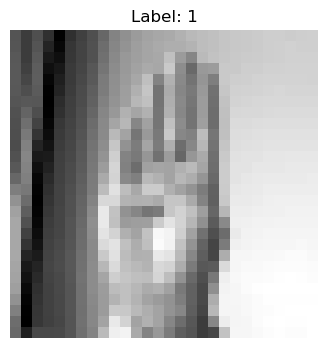

In [6]:
plt.figure(figsize=(4, 4))
image_index = 0
plt.imshow(X_train[image_index].reshape(28, 28), cmap='gray')
plt.title(f"Label: {y_train[image_index]}")
plt.axis('off')
plt.show()

## 4. Quick Recap: Activation Functions

> **Review**: We covered activation functions in detail in `01_Dense_Layers.ipynb`. Here's a quick reminder:

| Function | Formula | Use Case |
|----------|---------|----------|
| **ReLU** | `max(0, x)` | Hidden layers (most common) |
| **Sigmoid** | `1/(1+e^-x)` | Binary classification output |
| **Softmax** | Normalizes to probabilities | Multi-class classification output |

For our Sign Language classifier, we'll use:
- **ReLU** in hidden layers (fast training, avoids vanishing gradients)
- **Softmax** in output layer (25 classes → 25 probabilities)

## 5. Building the Model (Sequential API)

We will build a simple Feed-Forward Neural Network (Dense Neural Network).

-   **`Sequential()`**: Creates a linear stack of layers.
-   **`Dense(units, activation)`**: A fully connected layer.
-   **`Input(shape)`**: Defines the shape of the input data.

In [8]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Input

# Initialize model
model = Sequential()

# Input Layer (implicit) + First Hidden Layer
# 128 neurons, ReLU activation
model.add(Input(shape=(784,))) # 784 features (28*28)
model.add(Dense(128, activation='relu'))

# Second Hidden Layer
model.add(Dense(64, activation='relu'))

# Output Layer
# Units = number of classes. We have up to 25 classes (0-24).
# Activation = 'softmax' for multi-class probability
model.add(Dense(25, activation='softmax'))

# View model summary
model.summary()

2026-01-04 14:02:00.295285: I metal_plugin/src/device/metal_device.cc:1154] Metal device set to: Apple M1 Max
2026-01-04 14:02:00.295338: I metal_plugin/src/device/metal_device.cc:296] systemMemory: 32.00 GB
2026-01-04 14:02:00.295359: I metal_plugin/src/device/metal_device.cc:313] maxCacheSize: 12.48 GB
2026-01-04 14:02:00.295379: I tensorflow/core/common_runtime/pluggable_device/pluggable_device_factory.cc:305] Could not identify NUMA node of platform GPU ID 0, defaulting to 0. Your kernel may not have been built with NUMA support.
2026-01-04 14:02:00.295397: I tensorflow/core/common_runtime/pluggable_device/pluggable_device_factory.cc:271] Created TensorFlow device (/job:localhost/replica:0/task:0/device:GPU:0 with 0 MB memory) -> physical PluggableDevice (device: 0, name: METAL, pci bus id: <undefined>)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 25)             │         1,625 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 110,361 (431.10 KB)

 Trainable params: 110,361 (431.10 KB)

 Non-trainable params: 0 (0.00 B)

## 6. Compilation

Before training, we need to configure the learning process:
1.  **Optimizer**: Algorithms to update weights (e.g., `adam`, `sgd`). `adam` is a great default.
2.  **Loss Function**: Measures how wrong the model is. 
    -   `sparse_categorical_crossentropy`: For integer labels (like we have: 0, 1, 3...).
    -   `categorical_crossentropy`: If labels were one-hot encoded.
3.  **Metrics**: To monitor performance (e.g., `accuracy`).

In [9]:
model.compile(optimizer='adam',
              loss='sparse_categorical_crossentropy',
              metrics=['accuracy'])

## 7. Training (Fitting)

We train the model using `model.fit()`.
-   **`epochs`**: How many times the model sees the entire dataset.
-   **`batch_size`**: Number of samples processed before updating weights.
-   **`validation_split`**: Fraction of training data to use for validation during training.

In [10]:
history = model.fit(X_train, y_train,
                    epochs=10,
                    batch_size=32,
                    validation_split=0.1,
                    verbose=1)

Epoch 1/10


2026-01-04 14:02:03.728845: I tensorflow/core/grappler/optimizers/custom_graph_optimizer_registry.cc:117] Plugin optimizer for device_type GPU is enabled.


45/45 ━━━━━━━━━━━━━━━━━━━━ 4s 23ms/step - accuracy: 0.3961 - loss: 1.3569 - val_accuracy: 0.5938 - val_loss: 0.9484
Epoch 2/10
45/45 ━━━━━━━━━━━━━━━━━━━━ 1s 14ms/step - accuracy: 0.7165 - loss: 0.7251 - val_accuracy: 0.8375 - val_loss: 0.4901
Epoch 3/10
45/45 ━━━━━━━━━━━━━━━━━━━━ 1s 14ms/step - accuracy: 0.8742 - loss: 0.4149 - val_accuracy: 0.9438 - val_loss: 0.3622
Epoch 4/10
45/45 ━━━━━━━━━━━━━━━━━━━━ 1s 15ms/step - accuracy: 0.8833 - loss: 0.3351 - val_accuracy: 0.9750 - val_loss: 0.2097
Epoch 5/10
45/45 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step - accuracy: 0.9819 - loss: 0.1953 - val_accuracy: 0.9937 - val_loss: 0.1315
Epoch 6/10
45/45 ━━━━━━━━━━━━━━━━━━━━ 1s 14ms/step - accuracy: 0.9826 - loss: 0.1425 - val_accuracy: 0.9937 - val_loss: 0.1071
Epoch 7/10
45/45 ━━━━━━━━━━━━━━━━━━━━ 1s 14ms/step - accuracy: 0.9785 - loss: 0.1165 - val_accuracy: 0.9937 - val_loss: 0.0687
Epoch 8/10
45/45 ━━━━━━━━━━━━━━━━━━━━ 1s 15ms/step - accuracy: 0.9917 - loss: 0.0727 - val_accuracy: 1.0000 - val_loss: 0.

### Visualize Training History
It's crucial to plot Loss and Accuracy to check for overfitting or underfitting.

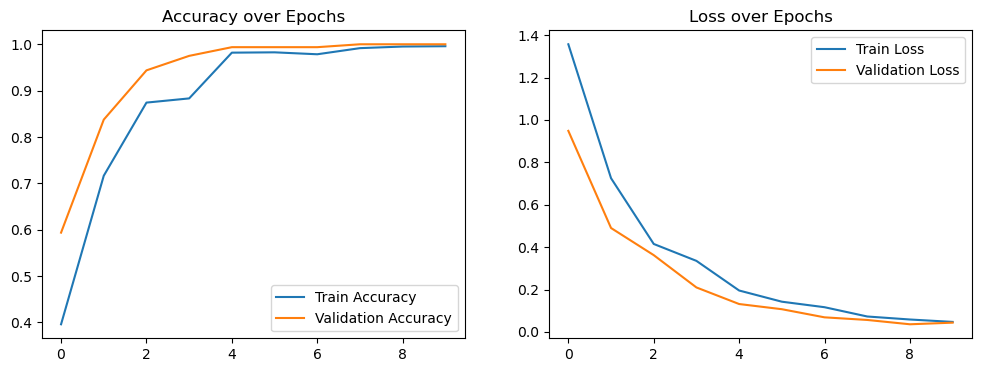

In [11]:
plt.figure(figsize=(12, 4))

# Plot Accuracy
plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='Train Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.title('Accuracy over Epochs')
plt.legend()

# Plot Loss
plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='Train Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('Loss over Epochs')
plt.legend()

plt.show()

## 8. Evaluation

Finally, we verify the performance on the independent **Test Set** that the model has never seen.

In [12]:
test_loss, test_acc = model.evaluate(X_test, y_test)
print(f"\nTest Accuracy: {test_acc:.4f}")

13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - accuracy: 0.9925 - loss: 0.0544

Test Accuracy: 0.9925


## 9. Exercises

Now it's your turn to experiment!

**Exercise 1: Change Architecture**
Create a new model called `model_ex` with:
- 3 Hidden Layers (units: 256, 128, 64)
- Train it for 10 epochs.
- Compare the Test Accuracy with the previous model.

**Exercise 2: Try a different Optimizer**
Retrain the original architecture but use `optimizer='sgd'` (Stochastic Gradient Descent). Does it converge faster or slower?

**Exercise 3: Confusion Matrix**
Use `sklearn.metrics.confusion_matrix` to identify which letters are most commonly confused by the model.

In [ ]:
# Exercise 1: Your Code Here
